# Dysbiosis Threshold Sweep for Differential Expression (Recalled Species)

Do any rare/core species definitions and dysbiosis cutoffs give a dysbiotic group with clear differential expression? At the current settings (rare < 10% prevalence, > 3% of reads) DESeq2 finds no significant genes (`transcriptomic_impact_of_dysbiosis_recalled_species.ipynb`).

Two families of definitions are swept:

1. **Rare-species excess** (the current rule): rare species = seasonal prevalence < `rare_prevalence_thresholds`; a sample is dysbiotic if its rare species make up more than a cutoff % of its reads.
2. **Core-species loss**: core species = seasonal prevalence > `core_prevalence_thresholds`; a sample is dysbiotic if its core species make up *less* than a cutoff % of its reads.

**Sweeping the dysbiotic cutoff:** the same % cutoff calls very different numbers of samples depending on the prevalence threshold (1% of reads in rare species is common when rare means < 30%, unusual when it means < 5%). So the cutoff is swept by group size instead: for each definition, the cutoff is set so that `group_sizes` (20, 40, 60, 100) samples are dysbiotic. The % cutoff each one corresponds to is reported. Groupings that give exactly the same samples are only fitted once.

**DESeq2:** `~timepoint + group` on all plates 1–5 transcriptomes with a microbiome profile, same gene filters as the main DE notebook. Two random groupings (60 samples) show what to expect with no real difference.

The defense score is only used to describe the groups afterwards (timepoint-adjusted difference between dysbiotic and the rest), never to define them.

Results of each run are cached in `Generated_data/dysbiosis_threshold_sweep_recalled_species/`. Delete that folder to refit everything.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
from pathlib import Path
import statsmodels.formula.api as smf
from scipy.stats import zscore
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds

###Define Thresholds
rare_prevalence_thresholds = [0.05, 0.1, 0.2, 0.3]
core_prevalence_thresholds = [0.7, 0.8, 0.9]
group_sizes = [20, 40, 60, 100]
n_random_groupings = 2
random_group_size = 60
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21
n_cpus = 6
results_dir = Path(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/dysbiosis_threshold_sweep_recalled_species"
)

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

# Same gene filters as the dysbiosis DE notebook
cleaned_raw_transcriptome = trimmed_raw_transcriptome.loc[
    :, trimmed_raw_transcriptome.sum() > expressed_gene_reads_threshold
]
cleaned_raw_transcriptome = cleaned_raw_transcriptome.loc[
    :, (cleaned_raw_transcriptome > 1).sum() > number_of_samples_expressed_in_threshold
]
print("Genes kept for DESeq2:", cleaned_raw_transcriptome.shape[1])

# Defense score: only used to describe the groups, never to define them
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
defense_genes = set(defense_gene_list["gene"])
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_genes)
]
trimmed_metadata["Defense Score"] = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)

# Old species-level DE genes (59, plates 1-5), for overlap
old_de_genes = set(
    pd.read_csv(
        "/Users/michael/Data/Luke_terrace_experiment/General_data/Junk_data/large_deseq_gene_list_all_plates.csv",
        header=None,
    )[0]
)

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426
Genes kept for DESeq2: 18032


## Species abundance

In [3]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0) are
### dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]

# Sample x species abundance as % of each sample's reads (absent species = 0)
species_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Species", aggfunc="sum", fill_value=0
)
species_abundance_matrix = species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
seasonal_prevalence = (species_abundance_matrix.loc[seasonal_samples] > 0).mean()

# Transcriptome samples, all with a microbiome profile
de_samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(species_abundance_matrix.index)]
print("Transcriptomes with a microbiome profile:", len(de_samples), "of", len(trimmed_metadata))
sample_species = species_abundance_matrix.loc[trimmed_metadata.loc[de_samples, "sampID"]].set_index(de_samples)

Transcriptomes with a microbiome profile: 426 of 426


## Groupings

For each definition and group size: the % cutoff is halfway between the n-th and (n+1)-th sample, as in `de_sensitivity_rare_species_20_percent.ipynb`.

In [4]:
def top_n_group(score, n, highest=True):
    """The n samples with the highest (or lowest) score, and the cutoff between them and the rest."""
    ordered = score.sort_values(ascending=not highest)
    cutoff = (ordered.iloc[n - 1] + ordered.iloc[n]) / 2
    return ordered.index[:n], cutoff


groupings = []
for prevalence in rare_prevalence_thresholds:
    rare = seasonal_prevalence.index[seasonal_prevalence < prevalence]
    rare_abund = sample_species[rare].sum(axis=1)
    for n in group_sizes:
        high_samples, cutoff = top_n_group(rare_abund, n, highest=True)
        groupings.append(
            {
                "definition": "rare excess",
                "prevalence threshold": prevalence,
                "n species": len(rare),
                "group size": n,
                "cutoff (% of reads)": round(cutoff, 3),
                "rule": f"rare (< {prevalence:.0%}) > {cutoff:.2f}%",
                "high_samples": high_samples,
            }
        )
for prevalence in core_prevalence_thresholds:
    core = seasonal_prevalence.index[seasonal_prevalence > prevalence]
    core_abund = sample_species[core].sum(axis=1)
    for n in group_sizes:
        high_samples, cutoff = top_n_group(core_abund, n, highest=False)
        groupings.append(
            {
                "definition": "core loss",
                "prevalence threshold": prevalence,
                "n species": len(core),
                "group size": n,
                "cutoff (% of reads)": round(cutoff, 3),
                "rule": f"core (> {prevalence:.0%}) < {cutoff:.2f}%",
                "high_samples": high_samples,
            }
        )
random_generator = np.random.default_rng(0)
for i in range(n_random_groupings):
    groupings.append(
        {
            "definition": "random",
            "prevalence threshold": np.nan,
            "n species": np.nan,
            "group size": random_group_size,
            "cutoff (% of reads)": np.nan,
            "rule": f"random {i + 1}",
            "high_samples": pd.Index(random_generator.choice(de_samples, random_group_size, replace=False)),
        }
    )

groupings = pd.DataFrame(groupings)
groupings["run_id"] = (
    groupings["definition"].str.replace(" ", "_")
    + "_prev"
    + groupings["prevalence threshold"].map(lambda p: "NA" if pd.isna(p) else f"{p:g}")
    + "_n"
    + groupings["group size"].astype(str)
    + groupings["rule"].str.extract(r"random (\d)")[0].fillna("").radd("_").replace("_", "")
)
# Identical sample sets are fitted once
groupings["sample_key"] = groupings["high_samples"].map(lambda s: tuple(sorted(s)))
groupings["duplicate of"] = groupings.groupby("sample_key")["run_id"].transform("first")
print(f"Groupings: {len(groupings)}, distinct sample sets: {groupings['sample_key'].nunique()}")
groupings.drop(columns=["high_samples", "sample_key"])

Groupings: 30, distinct sample sets: 30


,definition,prevalence threshold,n species,group size,cutoff (% of reads),rule,run_id,duplicate of
0,rare excess,0.05,377.0,20,2.649,rare (< 5%) > 2.65%,rare_excess_prev0.05_n20,rare_excess_prev0.05_n20
1,rare excess,0.05,377.0,40,1.854,rare (< 5%) > 1.85%,rare_excess_prev0.05_n40,rare_excess_prev0.05_n40
2,rare excess,0.05,377.0,60,1.347,rare (< 5%) > 1.35%,rare_excess_prev0.05_n60,rare_excess_prev0.05_n60
3,rare excess,0.05,377.0,100,0.863,rare (< 5%) > 0.86%,rare_excess_prev0.05_n100,rare_excess_prev0.05_n100
4,rare excess,0.10,434.0,20,5.287,rare (< 10%) > 5.29%,rare_excess_prev0.1_n20,rare_excess_prev0.1_n20
5,rare excess,0.10,434.0,40,3.859,rare (< 10%) > 3.86%,rare_excess_prev0.1_n40,rare_excess_prev0.1_n40
6,rare excess,0.10,434.0,60,2.813,rare (< 10%) > 2.81%,rare_excess_prev0.1_n60,rare_excess_prev0.1_n60
7,rare excess,0.10,434.0,100,1.757,rare (< 10%) > 1.76%,rare_excess_prev0.1_n100,rare_excess_prev0.1_n100
8,rare excess,0.20,493.0,20,9.498,rare (< 20%) > 9.50%,rare_excess_prev0.2_n20,rare_excess_prev0.2_n20
9,rare excess,0.20,493.0,40,6.490,rare (< 20%) > 6.49%,rare_excess_prev0.2_n40,rare_excess_prev0.2_n40


In [5]:
# How much the groupings overlap with the current calls (rare < 10%, > 3%)
current_calls = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/dysbiosis_calls_recalled_species.csv",
    index_col="sampID",
)
current_dysbiotic = de_samples[
    trimmed_metadata.loc[de_samples, "sampID"].map(current_calls["Dysbiosis Status"]).eq("Dysbiotic")
]
groupings["overlap with current calls"] = groupings["high_samples"].map(
    lambda s: len(set(s) & set(current_dysbiotic))
)
print("Current dysbiotic samples:", len(current_dysbiotic))
groupings.pivot_table(
    index=["definition", "prevalence threshold"], columns="group size", values="overlap with current calls"
)

Current dysbiotic samples: 52


group size                         20    40    60    100
definition  prevalence threshold                        
core loss   0.70                  12.0  20.0  30.0  39.0
            0.80                  12.0  19.0  27.0  38.0
            0.90                  11.0  18.0  25.0  35.0
rare excess 0.05                  20.0  34.0  40.0  46.0
            0.10                  20.0  40.0  52.0  52.0
            0.20                  19.0  32.0  41.0  51.0
            0.30                  18.0  32.0  41.0  48.0

## DESeq2 runs

About 2 minutes per run. Cached runs load instantly.

In [6]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=n_cpus)
de_counts = cleaned_raw_transcriptome.loc[de_samples]
results_dir.mkdir(parents=True, exist_ok=True)


def run_deseq(run_id, high_samples):
    """DESeq2 ~timepoint + group (High vs Low) on all DE samples. Results are cached
    in results_dir, so a re-run only fits groupings it hasn't seen."""
    cache = results_dir / f"{run_id}.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col=0)
    design_metadata = pd.DataFrame(
        {
            "timepoint": trimmed_metadata.loc[de_samples, "timepoint"],
            "group": np.where(de_samples.isin(high_samples), "High", "Low"),
        },
        index=de_samples,
    )
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        dds = pydeseq2.dds.DeseqDataSet(
            counts=de_counts,
            metadata=design_metadata,
            design="~timepoint+group",
            refit_cooks=True,
            inference=inference,
            quiet=True,
        )
        dds.deseq2()
        stats = pydeseq2.ds.DeseqStats(
            dds, contrast=["group", "High", "Low"], inference=inference, quiet=True
        )
        stats.summary()
    results = stats.results_df
    results.to_csv(cache)
    return results


def summarise_run(results, high_samples):
    """DE gene counts, plus how the group's defense score compares (timepoint-adjusted)."""
    significant = results.loc[results["padj"] < 0.05]
    defense_df = trimmed_metadata.loc[de_samples, ["timepoint", "Defense Score"]].assign(
        high=de_samples.isin(high_samples).astype(int)
    )
    fit = smf.ols("Q('Defense Score') ~ C(timepoint) + high", data=defense_df).fit()
    return {
        "n High": int(defense_df["high"].sum()),
        "significant (padj < 0.05)": len(significant),
        "up": int((significant["log2FoldChange"] > 0).sum()),
        "down": int((significant["log2FoldChange"] < 0).sum()),
        "significant, |LFC| > 1": int((significant["log2FoldChange"].abs() > 1).sum()),
        "min padj": results["padj"].min(),
        "defense genes among significant": len(set(significant.index) & defense_genes),
        "old DE genes among significant": len(set(significant.index) & old_de_genes),
        "defense score diff (timepoint-adjusted)": fit.params["high"],
        "defense score diff p": fit.pvalues["high"],
    }

In [7]:
sweep_rows = []
run_results = {}
for _, grouping in groupings.iterrows():
    run_id = grouping["duplicate of"]
    if run_id not in run_results:
        run_results[run_id] = run_deseq(run_id, grouping["high_samples"])
    sweep_rows.append(
        {
            **grouping.drop(["high_samples", "sample_key"]).to_dict(),
            **summarise_run(run_results[run_id], grouping["high_samples"]),
        }
    )
    print(f"{grouping['run_id']}: {sweep_rows[-1]['significant (padj < 0.05)']} significant genes")

sweep_results = pd.DataFrame(sweep_rows)
sweep_results.to_csv(results_dir / "sweep_summary.csv", index=False)

rare_excess_prev0.05_n20: 2 significant genes


rare_excess_prev0.05_n40: 0 significant genes


rare_excess_prev0.05_n60: 0 significant genes


rare_excess_prev0.05_n100: 0 significant genes


rare_excess_prev0.1_n20: 13 significant genes


rare_excess_prev0.1_n40: 7 significant genes


... (20 outputs left out)

core_loss_prev0.9_n60: 16 significant genes


core_loss_prev0.9_n100: 0 significant genes


random_prevNA_n60_1: 0 significant genes


random_prevNA_n60_2: 0 significant genes


## Results

In [8]:
summary_columns = [
    "definition", "prevalence threshold", "group size", "cutoff (% of reads)", "n species",
    "significant (padj < 0.05)", "up", "down", "significant, |LFC| > 1", "min padj",
    "defense genes among significant", "old DE genes among significant",
    "defense score diff (timepoint-adjusted)", "defense score diff p", "overlap with current calls",
]
sweep_results[summary_columns].round(4)

,definition,prevalence threshold,group size,cutoff (% of reads),n species,significant (padj < 0.05),up,down,"significant, |LFC| > 1",min padj,defense genes among significant,old DE genes among significant,defense score diff (timepoint-adjusted),defense score diff p,overlap with current calls
0,rare excess,0.05,20,2.649,377.0,2,2,0,1,0.0002,0,0,-0.0024,0.9817,20
1,rare excess,0.05,40,1.854,377.0,0,0,0,0,0.4451,0,0,-0.0610,0.4326,34
2,rare excess,0.05,60,1.347,377.0,0,0,0,0,0.4734,0,0,-0.0652,0.3115,40
3,rare excess,0.05,100,0.863,377.0,0,0,0,0,0.9996,0,0,-0.0786,0.1428,46
4,rare excess,0.10,20,5.287,434.0,13,6,7,1,0.0000,0,0,-0.0214,0.8450,20
5,rare excess,0.10,40,3.859,434.0,7,5,2,0,0.0004,0,2,-0.0278,0.7298,40
6,rare excess,0.10,60,2.813,434.0,0,0,0,0,0.1404,0,0,-0.1227,0.0770,52
7,rare excess,0.10,100,1.757,434.0,18,10,8,2,0.0039,0,0,-0.1139,0.0471,52
8,rare excess,0.20,20,9.498,493.0,52,17,35,12,0.0248,2,0,0.1777,0.1068,19
9,rare excess,0.20,40,6.490,493.0,2,0,2,0,0.0235,0,0,-0.0268,0.7531,32


Random groupings: [0, 0] significant genes


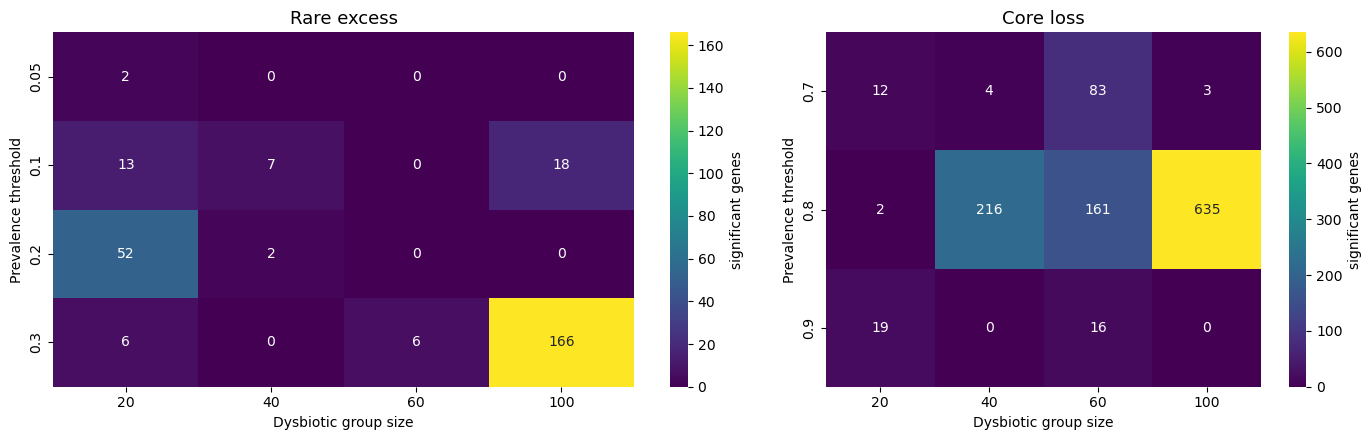

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [4, 3]})
fig.patch.set_facecolor("white")
for ax, definition in zip(axes, ["rare excess", "core loss"]):
    grid = sweep_results.loc[sweep_results["definition"] == definition].pivot(
        index="prevalence threshold", columns="group size", values="significant (padj < 0.05)"
    )
    sns.heatmap(grid, annot=True, fmt="d", cmap="viridis", cbar_kws={"label": "significant genes"}, ax=ax)
    ax.set_title(definition.capitalize(), fontsize=13)
    ax.set_xlabel("Dysbiotic group size")
    ax.set_ylabel("Prevalence threshold")
plt.tight_layout()
print(
    "Random groupings:",
    sweep_results.loc[sweep_results["definition"] == "random", "significant (padj < 0.05)"].tolist(),
    "significant genes",
)

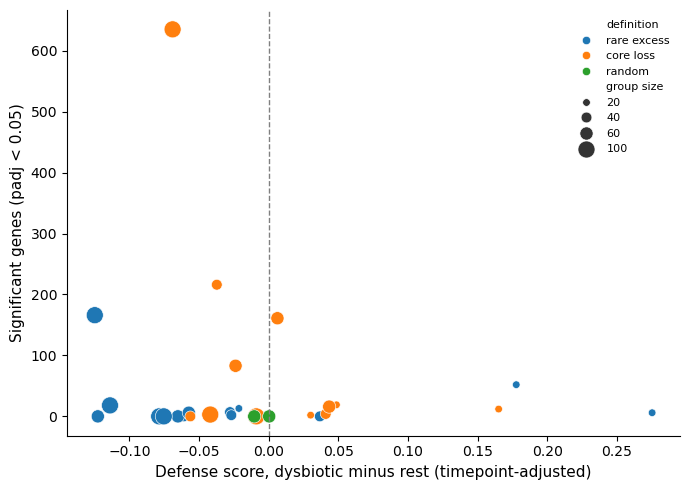

In [10]:
# Do the groupings that pick high-defense samples also give DE genes?
fig, ax = plt.subplots(figsize=(7, 5))
fig.patch.set_facecolor("white")
sns.scatterplot(
    data=sweep_results,
    x="defense score diff (timepoint-adjusted)",
    y="significant (padj < 0.05)",
    hue="definition",
    size="group size",
    sizes=(30, 150),
    ax=ax,
)
ax.axvline(0, color="gray", linestyle="dashed", linewidth=1)
ax.set_xlabel("Defense score, dysbiotic minus rest (timepoint-adjusted)", fontsize=11)
ax.set_ylabel("Significant genes (padj < 0.05)", fontsize=11)
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1, 1))
sns.despine()
plt.tight_layout()

## Best runs

Top genes of the three runs with the most significant genes (excluding random groupings).

In [11]:
best_runs = (
    sweep_results.loc[sweep_results["definition"] != "random"]
    .drop_duplicates("duplicate of")
    .sort_values("significant (padj < 0.05)", ascending=False)
    .head(3)
)
for _, run in best_runs.iterrows():
    results = run_results[run["duplicate of"]]
    significant = results.loc[results["padj"] < 0.05].sort_values("padj")
    print(f"\n=== {run['rule']} (n = {run['group size']}): {len(significant)} significant genes ===")
    display(
        significant.head(15)[["baseMean", "log2FoldChange", "padj"]]
        .assign(defense_gene=lambda df: df.index.isin(defense_genes))
        .round(4)
    )


=== core (> 80%) < 72.43% (n = 100): 635 significant genes ===


,baseMean,log2FoldChange,padj,defense_gene
AT5G17860,154.4654,-0.6736,0.0011,False
AT1G60000,599.5190,0.2247,0.0011,False
AT4G11360,179.3911,-0.4494,0.0011,False
AT5G28500,1881.8807,0.2840,0.0011,False
AT1G50010,837.0355,0.2453,0.0019,False
AT1G11310,190.7227,-0.2779,0.0020,False
AT5G38430,10633.4598,0.3355,0.0020,False
AT1G15920,52.3002,-0.4542,0.0020,False
AT4G28240,580.5203,-0.2963,0.0032,False
AT1G20330,254.6232,0.2445,0.0034,False



=== core (> 80%) < 62.71% (n = 40): 216 significant genes ===


,baseMean,log2FoldChange,padj,defense_gene
AT1G01120,1223.8450,0.4439,0.0004,False
AT5G45890,323.6307,-5.3248,0.0015,False
AT4G19960,167.2171,-0.5461,0.0019,False
AT4G35100,1044.9669,0.3839,0.0020,False
AT5G12040,195.8632,-0.3546,0.0030,False
AT5G59420,184.8780,-0.4398,0.0038,False
AT4G14870,123.2404,0.4271,0.0044,False
AT2G25625,120.8908,-1.1570,0.0044,False
AT1G23260,171.0913,-0.3476,0.0050,False
AT5G41410,106.4856,-0.4615,0.0050,False



=== rare (< 30%) > 6.05% (n = 100): 166 significant genes ===


,baseMean,log2FoldChange,padj,defense_gene
AT4G32590,308.2605,0.2522,0.0004,False
AT1G16080,252.7942,0.2912,0.0005,False
AT5G38420,11683.3922,0.4563,0.0006,False
AT4G04830,186.8113,0.7548,0.0013,False
AT5G35630,2069.6372,0.2788,0.0014,False
AT3G61870,1007.0408,0.2255,0.0014,False
AT3G01500,7094.6043,0.3347,0.0051,False
AT2G20870,218.1818,-0.7164,0.0051,False
AT5G38410,25130.4656,0.3928,0.0051,False
AT5G16710,315.2503,0.2272,0.0051,False
